# Pareto selection and reproducibility review

**New PSf stock bottle prepared November 5, 2026** (operator-provided). Fabrication dates come from the run export.

The [selection report](../docs/pareto_validation/index.html) and the [PSf](campaign_trends.ipynb) and [Primospire](primospire_nmp_campaign_trends.ipynb) trend notebooks provide the historical context. Validation IDs are specific to each chemistry. The Pareto plots compare historical recipe medians from the campaign trends exports with the medians from the November 5 bottle.

Each new fabrication contributes one aggregate observation. Coupon SD describes dispersion within a fabrication. The batch SD describes dispersion across fabrication means. The pipeline estimates pore fraction from compression curves. Blank cells indicate unavailable values.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'protocols/pareto_validation_plan.json').exists())
report = root / 'docs/pareto_validation'
campaign = 'psf-reproducibility-2026-11-16'
results = root / 'data/results' / f'begins_{campaign}'
bottle_prepared = pd.Timestamp('2026-11-05')
chemistries = {'psf': 'PSf / PolarClean', 'primospire': 'Primospire / NMP'}

selected = pd.concat([
    pd.read_csv(report / f'{slug}_selected_conditions.csv').assign(chemistry=chemistry)
    for slug, chemistry in chemistries.items()
], ignore_index=True)
audit = pd.read_csv(report / 'reproduction_samples.csv')
new = pd.concat([
    pd.read_csv(path).assign(batch=path.parent.name)
    for path in sorted(results.glob('*/reproduce.csv'))
], ignore_index=True)
new[['validation_id', 'repeat']] = new['name'].str.extract(r'_(V\d+)_rep(\d+)$')
assert new['validation_id'].notna().all() and new['name'].is_unique
new['repeat'] = new['repeat'].astype(int)
new['chemistry'] = chemistries['psf']
new['fabricated'] = pd.to_datetime(new['date'].str.replace(r'\s+', ' ', regex=True))
new['bottle age (days)'] = (new['fabricated'].dt.normalize() - bottle_prepared).dt.days

keys = ['chemistry', 'validation_id']
bulk = ['mixing_temp', 'bath_temp', 'polymer_wt', 'additive_wt', 'pullcast_speed',
        'nitrogen', 'coupon_to_bath_wait_time', 'nips_bath_wait_time',
        'polymer_type', 'solvent_type', 'cosolvent_type',
        'nips_bath_solvent', 'nips_bath_solvent_wt_percent']
settings = new.merge(selected[keys + bulk], on=keys, suffixes=('', '_selected'),
                     validate='many_to_one')
setting_issues = [
    {'sample': row['name'], 'field': field, 'batch': row[field],
     'selected': row[f'{field}_selected']}
    for _, row in settings.iterrows() for field in bulk
    if pd.isna(row[field]) or pd.isna(row[f'{field}_selected'])
    or row[field] != row[f'{field}_selected']
]
if setting_issues:
    display(pd.DataFrame(setting_issues))
else:
    print('All new samples match the selected recipe on all 13 recorded settings.')
if len(settings) != len(new):
    raise ValueError('New results include an ID missing from the selection.')

All new samples match the selected recipe on all 13 recorded settings.


## Selected samples and measurement coverage

The planned repeat count is per chemistry and recipe. A recorded fabrication can have missing properties. Selection reasons and historical repeat counts are reproduced from the frozen exports.

In [2]:
coverage = selected.merge(new.groupby(keys).size().rename('fabrications recorded'),
                          on=keys, how='left', validate='one_to_one')
coverage['fabrications recorded'] = coverage['fabrications recorded'].fillna(0).astype(int)
display(coverage[keys + ['condition', 'selection_reason', 'paired_samples',
                         'sample_repeats', 'fabrications recorded']])
display(selected[keys + ['bath_temp', 'polymer_wt', 'mixing_temp', 'pullcast_speed',
                         'nitrogen', 'coupon_to_bath_wait_time', 'nips_bath_wait_time',
                         'nips_bath_solvent', 'nips_bath_solvent_wt_percent',
                         'stock_solution_prepared', 'Toe Fit Mode']])

,chemistry,validation_id,condition,selection_reason,paired_samples,sample_repeats,fabrications recorded
0,PSf / PolarClean,V1,17-0add-13deg-cosolv-none-bathSolv-none-0wt-10...,Repeat-supported modulus anchor,5,3,3
1,PSf / PolarClean,V2,17-0add-16deg-cosolv-none-bathSolv-none-0wt-12...,Promising candidate adding tradeoff coverage,4,3,3
2,PSf / PolarClean,V3,14p5-0add-10deg-cosolv-none-bathSolv-PolarClea...,Promising limited-repeat validation opportunit...,2,3,0
3,PSf / PolarClean,V4,15-0add-9deg-cosolv-none-bathSolv-none-0wt-250...,Repeat-supported balanced candidate,10,3,3
4,PSf / PolarClean,V5,14p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,Repeat-supported pore-fraction anchor; matched...,4,3,0
5,Primospire / NMP,V1,18-0add-12deg-cosolv-none-bathSolv-none-0wt-90...,Promising candidate adding tradeoff coverage,4,3,0
6,Primospire / NMP,V2,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,Repeat-supported balanced candidate,3,3,0
7,Primospire / NMP,V3,19-0add-5deg-cosolv-none-bathSolv-none-0wt-0s-...,Repeat-supported modulus anchor,4,3,0
8,Primospire / NMP,V4,18p5-0add-5deg-cosolv-none-bathSolv-none-0wt-1...,Promising limited-repeat validation opportunity,2,3,0
9,Primospire / NMP,V5,18-0add-15deg-cosolv-none-bathSolv-none-0wt-60...,Repeat-supported pore-fraction anchor,5,3,0


,chemistry,validation_id,bath_temp,polymer_wt,mixing_temp,pullcast_speed,nitrogen,coupon_to_bath_wait_time,nips_bath_wait_time,nips_bath_solvent,nips_bath_solvent_wt_percent,stock_solution_prepared,Toe Fit Mode
0,PSf / PolarClean,V1,13,17.0,25,15.0,True,100,1800,none,0.0,2026-10-05,legacy
1,PSf / PolarClean,V2,16,17.0,25,15.0,True,120,1800,none,0.0,2026-09-10,legacy
2,PSf / PolarClean,V3,10,14.5,45,7.0,True,200,1500,PolarClean,10.0,2026-10-05,legacy
3,PSf / PolarClean,V4,9,15.0,40,6.0,True,250,1600,none,0.0,2026-10-05,legacy
4,PSf / PolarClean,V5,10,14.5,45,7.0,True,200,1500,none,0.0,2026-10-05,legacy
5,Primospire / NMP,V1,12,18.0,65,10.0,True,90,1800,none,0.0,2026-10-29,legacy
6,Primospire / NMP,V2,10,17.5,65,6.0,True,15,1800,none,0.0,2026-09-08,legacy
7,Primospire / NMP,V3,5,19.0,60,3.0,True,0,1500,none,0.0,2026-09-08,legacy
8,Primospire / NMP,V4,5,18.5,65,11.0,True,105,1800,none,0.0,2026-09-08,legacy
9,Primospire / NMP,V5,15,18.0,80,15.0,False,600,1350,none,0.0,2026-09-29,legacy


### November 16–17 results

- **V1:** Median modulus was 221 bar, 28% below the historical recipe median. Pore fraction increased from 0.449 to 0.495. One of two coupon fits was discarded in each of fabrications 2 and 3 for a plateau slope at or above the elastic modulus with no real transition.
- **V2:** Median modulus was 206 bar, 24% below the historical median. Pore fraction fell from 0.598 to 0.506. V2 had the widest spread in modulus (158–256 bar across three fabrications).
- **V4:** Median modulus was 153 bar, 35% below the historical median. Pore fraction fell from 0.648 to 0.594. V4 retained the highest median pore fraction among the three measured recipes.

The three new recipe medians show a modulus–pore fraction tradeoff. PSf V3 and V5 and all five Primospire selections lack results in this batch. The bottle was 11–12 calendar days old at fabrication. These comparisons cannot isolate a bottle or age effect because the historical and new runs can also differ in coupon sampling, ambient conditions, and fit settings.

## Typical measured performance by recipe

Elastic modulus is on the vertical axis and pore fraction is on the horizontal axis. As in the campaign trends notebooks, each point combines the two property medians across samples with both outcomes available. The two medians can come from different fabrications. The historical recipe points and dashed fronts come from the saved campaign trends exports. Hollow diamonds highlight the historical medians for the validation selections. Circles show the new recipe medians, labeled with the number of paired fabrications. The solid line connects nondominated medians within the new batch. Both objectives are maximized.

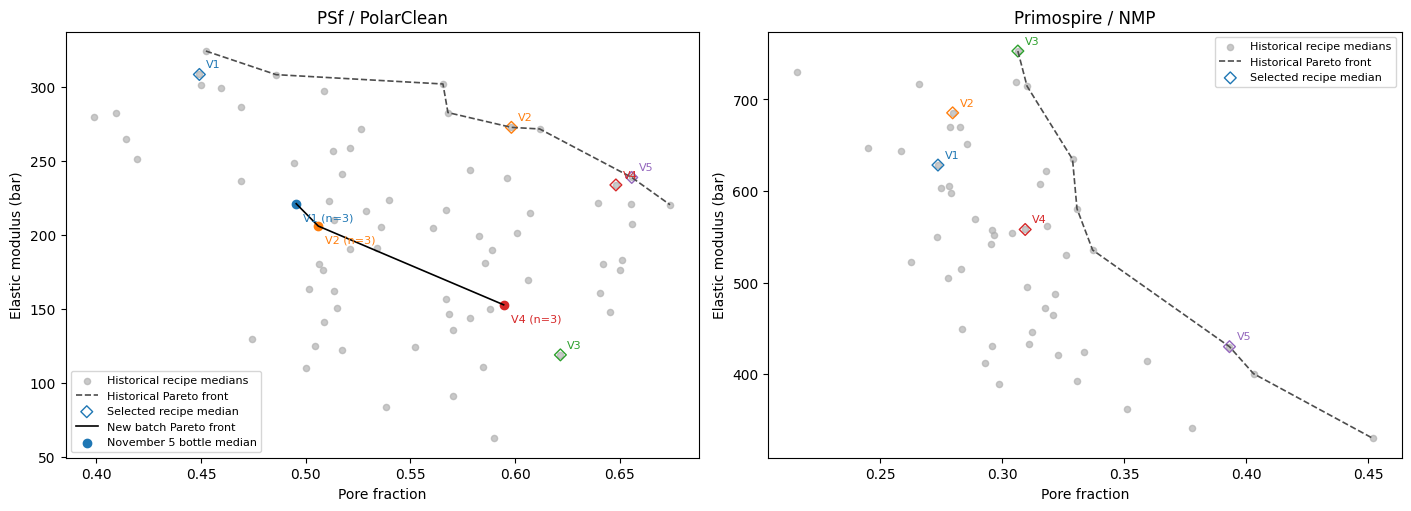

,chemistry,validation_id,Elastic Modulus Mean,Pore Fraction Mean,paired n
0,PSf / PolarClean,V1,221.1530,0.4955,3
1,PSf / PolarClean,V2,206.0751,0.5060,3
2,PSf / PolarClean,V4,152.9151,0.5945,3


In [3]:
objectives = ['Elastic Modulus Mean', 'Pore Fraction Mean']
historical_medians = ['Elastic Modulus median', 'Pore Fraction median']
colors = dict(zip(['V1', 'V2', 'V3', 'V4', 'V5'], plt.get_cmap('tab10').colors))
paired = new.dropna(subset=objectives)
groups = paired.groupby(keys)
new_centers = groups[objectives].median().join(groups.size().rename('paired n')).reset_index()
trend_outputs = {
    'PSf / PolarClean': 'campaign_trends_output',
    'Primospire / NMP': 'primospire_nmp_campaign_trends_output',
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
for ax, chemistry in zip(axes, chemistries.values()):
    path = root / 'EVALUATE' / trend_outputs[chemistry] / 'typical_recipe_pareto.csv'
    history = pd.read_csv(path).dropna(subset=historical_medians)
    y, x = historical_medians
    ax.scatter(history[x], history[y], c='0.68', s=20, alpha=.65,
               label='Historical recipe medians')
    historical_front = history.loc[history['pareto_optimal'].eq(True)].sort_values(x)
    ax.plot(historical_front[x], historical_front[y], '--', c='0.3', lw=1.2,
            label='Historical Pareto front')
    choices = selected.loc[selected['chemistry'].eq(chemistry)]
    for i, (_, row) in enumerate(choices.iterrows()):
        vid = row['validation_id']
        ax.scatter(row[x], row[y], facecolors='none', edgecolors=[colors[vid]], marker='D',
                   label='Selected recipe median' if i == 0 else None)
        ax.annotate(vid, (row[x], row[y]), xytext=(5, 5), textcoords='offset points',
                    color=colors[vid], fontsize=8)
    centers = new_centers.loc[new_centers['chemistry'].eq(chemistry)]
    if len(centers):
        y_new, x_new = objectives
        points = centers[objectives].to_numpy()
        nondominated = [
            not (((points >= point).all(axis=1)) & ((points > point).any(axis=1))).any()
            for point in points
        ]
        front = centers.loc[nondominated].sort_values(x_new)
        ax.plot(front[x_new], front[y_new], c='black', lw=1.2, label='New batch Pareto front')
        for i, (_, row) in enumerate(centers.iterrows()):
            vid = row['validation_id']
            ax.scatter(row[x_new], row[y_new], c=[colors[vid]], marker='o',
                       label='November 5 bottle median' if i == 0 else None)
            ax.annotate(f"{vid} (n={row['paired n']})", (row[x_new], row[y_new]),
                        xytext=(5, -12), textcoords='offset points', color=colors[vid], fontsize=8)
    ax.set(title=chemistry, xlabel='Pore fraction', ylabel='Elastic modulus (bar)')
    ax.legend(fontsize=8)
plt.show()
display(new_centers.round(4))

## Measured properties and batch shifts

The reference for modulus and pore fraction is the historical recipe median used for selection. For other properties, the reference is the selected historical sample because the selection export supplies no recipe median. Delta is the new median minus its reference. The range and SD use the available fabrication means for each property. This descriptive comparison has no prespecified acceptance tolerance.

In [4]:
units = {
    'Thickness': 'um', 'Elastic Modulus': 'bar', 'Yield Strength': 'bar',
    'Pore Fraction': 'fraction', 'Pore Fraction Unsubtracted': 'fraction',
    'Slope Plateau': 'bar', 'Slope Densification': 'bar', 'Creep Strain': 'strain',
    **{f'Strain at {bar} bar': 'strain' for bar in (50, 80, 150, 500)},
    'CV': 'fraction', 'Air Temp': 'deg C', 'Humidity': '%',
    'Coupon Temp': 'deg C', 'Coupon Humidity': '%',
}
means = [f'{prop} Mean' for prop in units]
sds = [f'{prop} SD' for prop in units if f'{prop} SD' in new]
props = {f'{prop} Mean': prop for prop in units}

summaries = []
for (chemistry, vid), samples in new.groupby(keys):
    ref = selected.loc[selected['chemistry'].eq(chemistry)
                       & selected['validation_id'].eq(vid)].iloc[0]
    for prop in means:
        values = samples[prop].dropna()
        median = values.median() if len(values) else float("nan")
        median_col = prop.replace(' Mean', ' median')
        has_recipe_median = prop in objectives and pd.notna(ref[median_col])
        reference = ref[median_col] if has_recipe_median else ref[prop]
        summaries.append({
            'ID': vid, 'property': props[prop], 'unit': units[props[prop]],
            'reference basis': 'Recipe median' if has_recipe_median else 'Selected sample',
            'reference': reference, 'n': values.count(), 'new median': median,
            'new min': values.min(), 'new max': values.max(), 'between-fabrication SD': values.std(),
            'delta': median - reference,
        })
summary = pd.DataFrame(summaries)
display(summary.loc[summary['property'].isin(['Elastic Modulus', 'Pore Fraction'])].round(4))
with pd.option_context('display.max_rows', None):
    display(summary.round(4))

,ID,property,unit,reference basis,reference,n,new median,new min,new max,between-fabrication SD,delta
1,V1,Elastic Modulus,bar,Recipe median,308.4650,3,221.1530,203.0954,230.9484,14.1293,-87.3120
3,V1,Pore Fraction,fraction,Recipe median,0.4492,3,0.4955,0.4878,0.5987,0.0619,0.0462
18,V2,Elastic Modulus,bar,Recipe median,272.7407,3,206.0751,158.4442,256.0428,48.8040,-66.6657
20,V2,Pore Fraction,fraction,Recipe median,0.5982,3,0.5060,0.4431,0.5257,0.0432,-0.0922
35,V4,Elastic Modulus,bar,Recipe median,233.8500,3,152.9151,131.4403,166.7402,17.7875,-80.9349
37,V4,Pore Fraction,fraction,Recipe median,0.6481,3,0.5945,0.5420,0.6155,0.0378,-0.0536


,ID,property,unit,reference basis,reference,n,new median,new min,new max,between-fabrication SD,delta
0,V1,Thickness,um,Selected sample,146.0050,3,134.9724,132.6451,142.5790,5.1955,-11.0326
1,V1,Elastic Modulus,bar,Recipe median,308.4650,3,221.1530,203.0954,230.9484,14.1293,-87.3120
2,V1,Yield Strength,bar,Selected sample,37.4944,3,33.3629,31.2108,40.3954,4.8036,-4.1315
3,V1,Pore Fraction,fraction,Recipe median,0.4492,3,0.4955,0.4878,0.5987,0.0619,0.0462
4,V1,Pore Fraction Unsubtracted,fraction,Selected sample,0.4710,3,0.5509,0.4878,0.5987,0.0556,0.0800
5,V1,Slope Plateau,bar,Selected sample,155.1207,3,85.0733,83.8333,121.9937,21.6829,-70.0474
6,V1,Slope Densification,bar,Selected sample,363.2414,3,480.5198,429.7669,599.7254,87.2466,117.2784
7,V1,Creep Strain,strain,Selected sample,0.1041,3,0.0728,0.0572,0.1673,0.0596,-0.0313
8,V1,Strain at 50 bar,strain,Selected sample,0.2331,3,0.3852,0.3368,0.3912,0.0298,0.1521
9,V1,Strain at 80 bar,strain,Selected sample,0.4115,3,0.5655,0.4693,0.5880,0.0630,0.1540


## Historical and new distributions by condition

Each cross is the mean for one historical sample in the audit with exact recorded recipe settings and raw specimen files. Historical values come from the campaign aggregate export using the existing post-discard preference. Each circle is one new fabrication mean, and its error bar shows the recorded within-fabrication SD when available. Horizontal jitter keeps points visible. Hollow diamonds retain the original comparison references described above. Counts vary by property because some fits or measurements are unavailable.

In [5]:
import sys
from matplotlib.lines import Line2D

sys.path.insert(0, str(root / 'EVALUATE'))
from campaign_trends import load_campaign_data

members = audit.loc[audit['match'].eq('exact recorded settings')
                    & audit['raw_specimens'].gt(0), keys + ['campaign', 'condition']]
history = load_campaign_data(campaigns=members['campaign'].unique())
history = members.merge(history[['campaign', 'condition'] + means],
                        on=['campaign', 'condition'], how='left', validate='many_to_one',
                        indicator=True)
unmatched = history.loc[history['_merge'].ne('both'), keys + ['campaign', 'condition']]
if len(unmatched):
    print('Historical audit entries without a matching aggregate:')
    display(unmatched)

historical_long = history.melt(id_vars=keys + ['condition'], value_vars=means,
                               var_name='metric', value_name='measurement')
historical_stats = historical_long.groupby(keys + ['metric'])['measurement'].agg(
    historical_n='count', historical_min='min', historical_median='median',
    historical_max='max', historical_SD='std')
new_long = new.melt(id_vars=keys, value_vars=means, var_name='metric', value_name='measurement')
new_stats = new_long.groupby(keys + ['metric'])['measurement'].agg(
    new_n='count', new_min='min', new_median='median', new_max='max', new_SD='std')
distribution = historical_stats.join(new_stats)
distribution['new_n'] = distribution['new_n'].fillna(0).astype(int)
with pd.option_context('display.max_rows', None):
    display(distribution.loc[(distribution['historical_n'] + distribution['new_n']).gt(0)].round(4))


historical_n  \
chemistry        validation_id metric                                          
PSf / PolarClean V1            Air Temp Mean                               5   
                               CV Mean                                     5   
                               Coupon Humidity Mean                        5   
                               Coupon Temp Mean                            5   
                               Creep Strain Mean                           5   
                               Elastic Modulus Mean                        5   
                               Humidity Mean                               5   
                               Pore Fraction Mean                          5   
                               Pore Fraction Unsubtracted Mean             5   
                               Slope Densification Mean                    5   
                               Slope Plateau Mean                          5   
                               Strain at 150 bar Mean                      4   
                               Strain at 50 bar Mean                       5   
                               Strain at 80 bar Mean                       5   
                               Thickness Mean                              5   
                               Yield Strength Mean                         5   
                 V2            Air Temp Mean                               4   
                               CV Mean                                     4   
                               Coupon Humidity Mean                        4   
                               Coupon Temp Mean                            4   
                               Creep Strain Mean                           4   
                               Elastic Modulus Mean                        4   
                               Humidity Mean                               4   
                               Pore Fraction Mean                          4   
                               Pore Fraction Unsubtracted Mean             4   
                               Slope Densification Mean                    4   
                               Slope Plateau Mean                          4   
                               Strain at 150 bar Mean                      3   
                               Strain at 50 bar Mean                       4   
                               Strain at 80 bar Mean                       4   
                               Thickness Mean                              4   
                               Yield Strength Mean                         4   
                 V3            Air Temp Mean                               2   
                               CV Mean                                     2   
                               Coupon Humidity Mean                        2   
                               Coupon Temp Mean                            2   
                               Creep Strain Mean                           2   
                               Elastic Modulus Mean                        2   
                               Humidity Mean                               2   
                               Pore Fraction Mean                          2   
                               Pore Fraction Unsubtracted Mean             2   
                               Slope Densification Mean                    2   
                               Slope Plateau Mean                          2   
                               Strain at 150 bar Mean                      2   
                               Strain at 50 bar Mean                       2   
                               Strain at 80 bar Mean                       2   
                               Thickness Mean                              2   
                               Yield Strength Mean                         2   
                 V4            Air Temp Mean                    

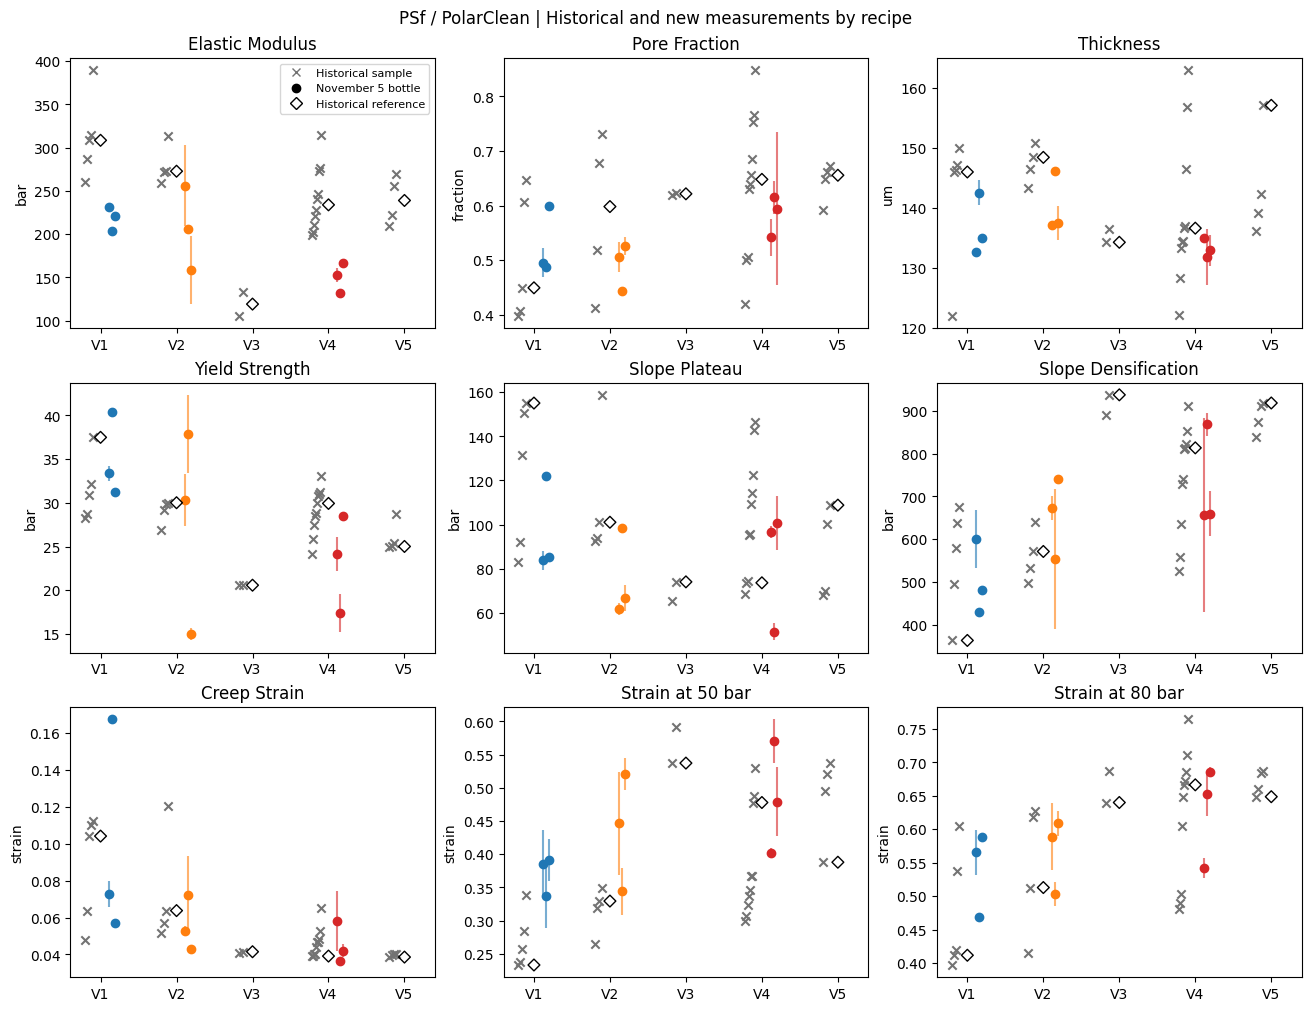

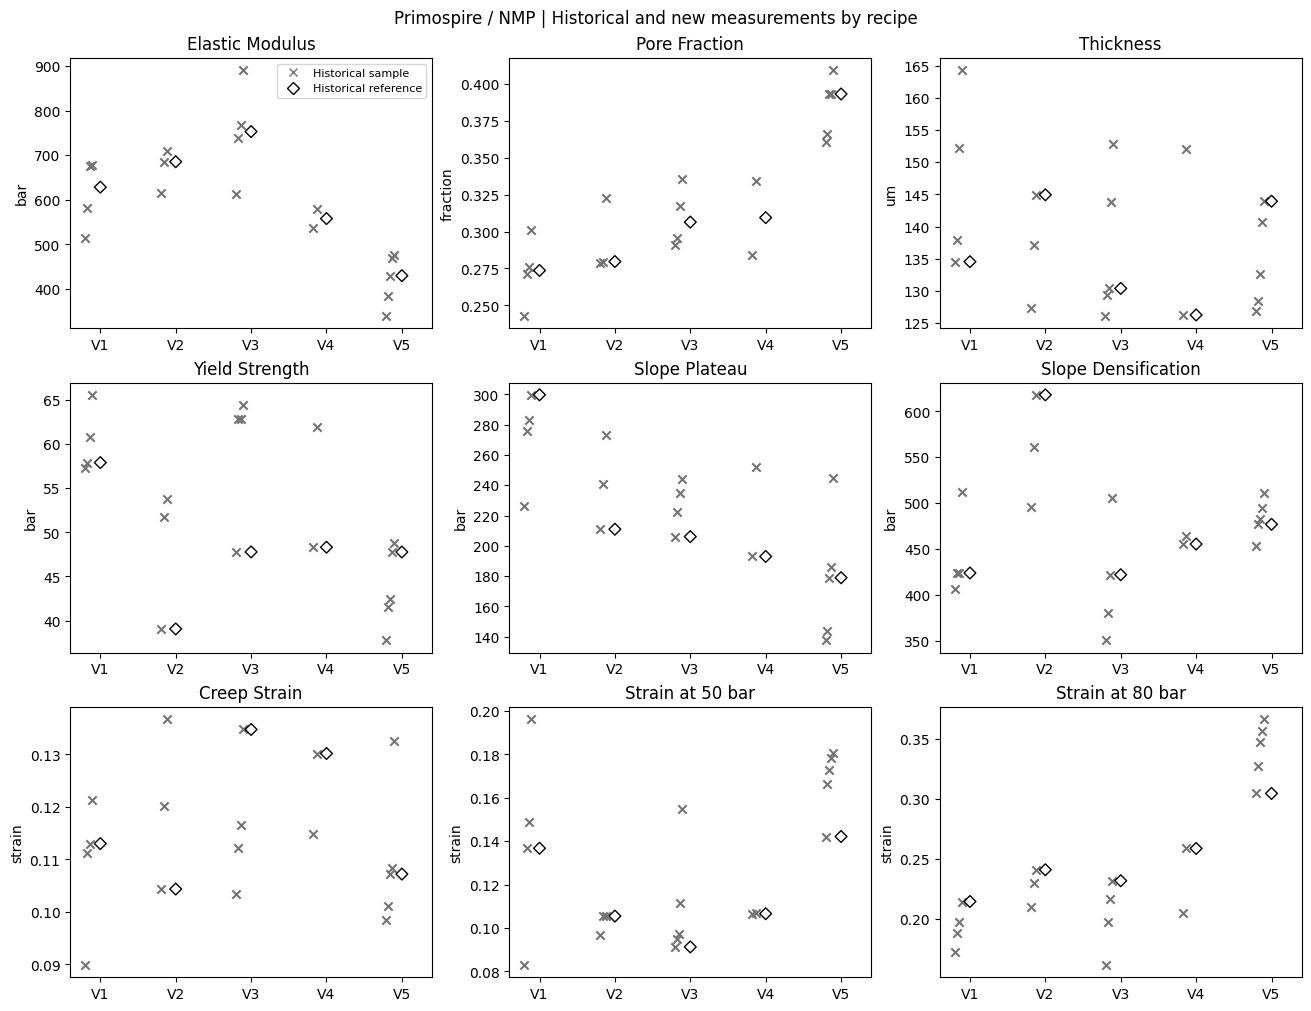

In [6]:
plot_props = ['Elastic Modulus', 'Pore Fraction', 'Thickness', 'Yield Strength',
              'Slope Plateau', 'Slope Densification', 'Creep Strain',
              'Strain at 50 bar', 'Strain at 80 bar']
legend = [
    Line2D([], [], color='0.45', marker='x', linestyle='none', label='Historical sample'),
    Line2D([], [], color='black', marker='o', linestyle='none', label='November 5 bottle'),
    Line2D([], [], color='black', marker='D', markerfacecolor='none', linestyle='none',
           label='Historical reference'),
]
for chemistry in chemistries.values():
    choices = selected.loc[selected['chemistry'].eq(chemistry)].set_index('validation_id')
    hist = history.loc[history['chemistry'].eq(chemistry)].sort_values('condition')
    fresh = new.loc[new['chemistry'].eq(chemistry)].sort_values('repeat')
    fig, axes = plt.subplots(3, 3, figsize=(13, 10), layout='constrained')
    for panel, (ax, prop) in enumerate(zip(axes.flat, plot_props)):
        metric = f'{prop} Mean'
        for x, (vid, ref) in enumerate(choices.iterrows()):
            hist_values = hist.loc[hist['validation_id'].eq(vid), metric].dropna()
            ax.scatter(x - .23 + hist_values.rank(method='first').to_numpy()
                       * .15 / (len(hist_values) + 1), hist_values, marker='x', color='0.45')
            samples = fresh.loc[fresh['validation_id'].eq(vid)].dropna(subset=[metric])
            if len(samples):
                positions = x + .08 + samples['repeat'].rank() * .15 / (len(samples) + 1)
                ax.scatter(positions, samples[metric], color=colors[vid])
                sd_col = f'{prop} SD'
                with_sd = samples[sd_col].notna()
                if with_sd.any():
                    ax.errorbar(positions[with_sd], samples.loc[with_sd, metric],
                                yerr=samples.loc[with_sd, sd_col], fmt='none',
                                color=colors[vid], alpha=.6)
            reference = ref[prop + ' median'] if metric in objectives else ref[metric]
            if pd.notna(reference):
                ax.scatter(x, reference, marker='D', facecolors='none', edgecolors='black')
        ax.set(title=prop, ylabel=units[prop], xticks=range(len(choices)),
               xticklabels=choices.index, xlim=(-.4, len(choices) - .6))
        if panel == 0:
            ax.legend(handles=legend if len(fresh) else [legend[0], legend[2]], fontsize=8)
    fig.suptitle(f'{chemistry} | Historical and new measurements by recipe')
    plt.show()


## Environmental inputs and stock-solution age

Compare the November 5 bottle fabrications with historical PSf samples of the same recorded recipe. The comparison includes air and coupon temperature and relative humidity as recorded in the aggregate exports. The 13 matching recipe fields include the bath and mixing temperature settings, casting speed, polymer concentration, and exposure and immersion times.

Historical bottle assignments follow the [PSf campaign trends notebook](campaign_trends.ipynb). The September 25 campaign used the September 10 bottle, and the October 15 campaign used the October 5 bottle. For this section, both groups use the campaign trends convention that timestamps at or before 09:00 count toward the previous experimental day. The new timestamps come from the run export. The historical sample timestamps come from the reproduction audit. The fabrication tables elsewhere show calendar bottle age. Missing sensor readings stay blank.

historical n  historical min  \
ID input                                                         
V1 Air relative humidity (%)                 5           29.22   
   Air temperature (deg C)                   5           24.54   
   Coupon relative humidity (%)              5            8.31   
   Coupon temperature (deg C)                5           24.41   
   Stock age (experimental days)             5           10.00   
V2 Air relative humidity (%)                 4           32.21   
   Air temperature (deg C)                   4           24.65   
   Coupon relative humidity (%)              4           33.47   
   Coupon temperature (deg C)                4           24.34   
   Stock age (experimental days)             4           15.00   
V4 Air relative humidity (%)                10           24.30   
   Air temperature (deg C)                  10           25.43   
   Coupon relative humidity (%)             10            3.78   
   Coupon temperature (deg C)               10           25.45   
   Stock age (experimental days)            10           14.00   

                                  historical median  historical max  new n  \
ID input                                                                     
V1 Air relative humidity (%)                  44.30           47.94      3   
   Air temperature (deg C)                    24.57           24.93      3   
   Coupon relative humidity (%)               44.80           45.89      3   
   Coupon temperature (deg C)                 24.47           25.10      3   
   Stock age (experimental days)              18.00           18.00      3   
V2 Air relative humidity (%)                  35.11           37.16      3   
   Air temperature (deg C)                    24.73           24.80      3   
   Coupon relative humidity (%)               38.59           41.16      3   
   Coupon temperature (deg C)                 24.54           24.58      3   
   Stock age (experimental days)              15.00           15.00      3   
V4 Air relative humidity (%)                  27.72           32.83      3   
   Air temperature (deg C)                    25.57           25.81      3   
   Coupon relative humidity (%)                5.90            9.92      3   
   Coupon temperature (deg C)                 25.58           25.88      3   
   Stock age (experimental days)              15.00           16.00      3   

                                  new min  new median  new max  median change  
ID input                                                                       
V1 Air relative humidity (%)        26.11       26.35    27.44         -17.95  
   Air temperature (deg C)          24.43       24.66    24.82           0.09  
   Coupon relative humidity (%)     26.68       27.77    28.69         -17.03  
   Coupon temperature (deg C)       24.50       24.55    24.72           0.08  
   Stock age (experimental days)    11.00       11.00    11.00          -7.00  
V2 Air relative humidity (%)        25.28       25.46    26.15          -9.65  
   Air temperature (deg C)          24.62       24.65    24.70          -0.08  
   Coupon relative humidity (%)     26.08       26.20    26.30         -12.39  
   Coupon temperature (deg C)       24.47       24.52    24.58          -0.02  
   Stock age (experimental days)    11.00       11.00    11.00          -4.00  
V4 Air relative humidity (%)        23.93       24.00    24.32          -3.72  
   Air temperature (deg C)          25.11       25.11    25.13          -0.46  
   Coupon relative humidity (%)     25.88       26.03    26.10          20.12  
   Coupon temperature (deg C)       25.27       25.29    25.29          -0.29  
   Stock age (experimental days)    11.00       11.00    12.00          -4.00

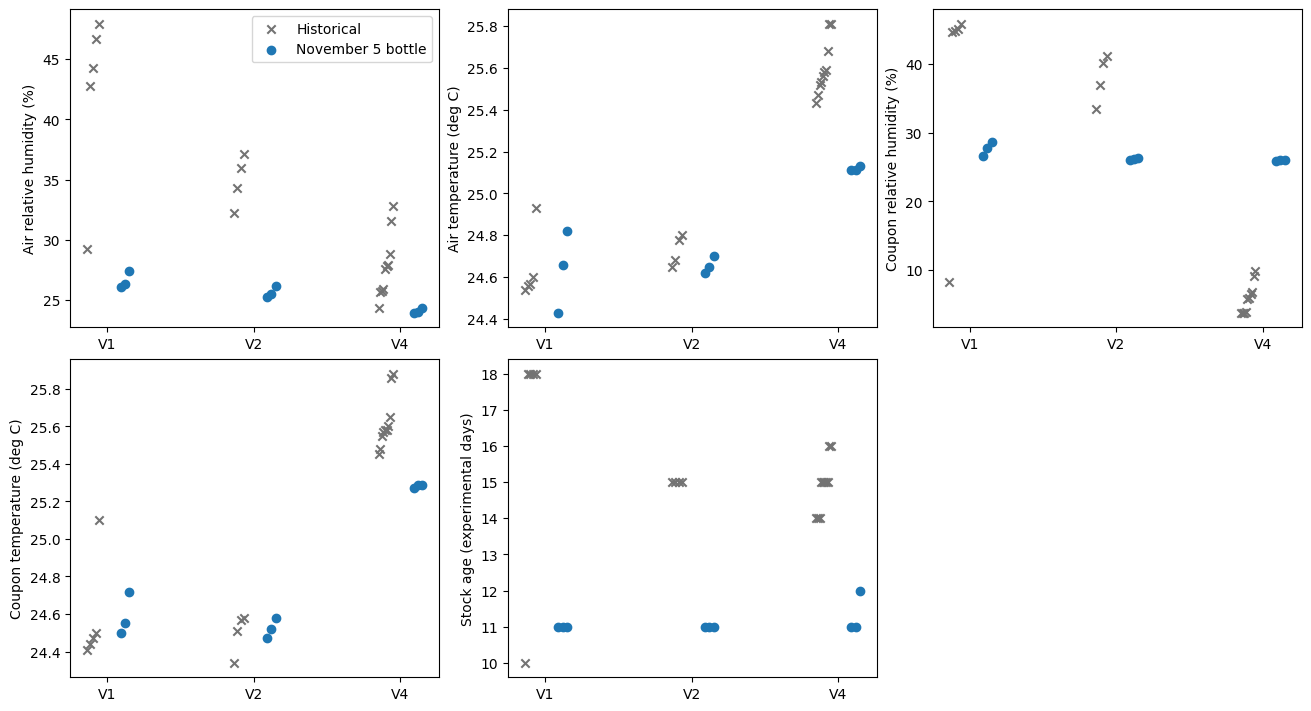

,validation_id,group,sample,timestamp,bottle prepared,Humidity Mean,Air Temp Mean,Coupon Humidity Mean,Coupon Temp Mean,experimental age
0,V1,Historical,17-0add-13deg-cosolv-none-bathSolv-none-0wt-10...,2026-09-28 21:08:40,2026-09-10,46.68,24.54,45.89,24.50,18
1,V1,Historical,17-0add-13deg-cosolv-none-bathSolv-none-0wt-10...,2026-09-28 22:31:01,2026-09-10,42.81,24.57,45.19,24.44,18
2,V1,Historical,17-0add-13deg-cosolv-none-bathSolv-none-0wt-10...,2026-09-28 23:47:04,2026-09-10,44.30,24.56,44.69,24.47,18
3,V1,Historical,17-0add-13deg-cosolv-none-bathSolv-none-0wt-10...,2026-09-29 01:06:01,2026-09-10,47.94,24.60,44.80,24.41,18
4,V1,Historical,17-0add-13deg-cosolv-none-bathSolv-none-0wt-10...,2026-10-15 19:16:52,2026-10-05,29.22,24.93,8.31,25.10,10
0,V1,November 5 bottle,psf-reproducibility-2026-11-16_psf-water_V1_rep1,2026-11-16 18:10:12,2026-11-05,27.44,24.43,28.69,24.50,11
1,V1,November 5 bottle,psf-reproducibility-2026-11-16_psf-water_V1_rep2,2026-11-16 19:41:44,2026-11-05,26.35,24.82,27.77,24.72,11
2,V1,November 5 bottle,psf-reproducibility-2026-11-16_psf-water_V1_rep3,2026-11-16 21:12:10,2026-11-05,26.11,24.66,26.68,24.55,11
5,V2,Historical,17-0add-16deg-cosolv-none-bathSolv-none-0wt-12...,2026-09-25 23:21:36,2026-09-10,37.16,24.65,41.16,24.57,15
6,V2,Historical,17-0add-16deg-cosolv-none-bathSolv-none-0wt-12...,2026-09-26 00:37:10,2026-09-10,35.95,24.78,40.20,24.51,15


In [7]:
environment = {
    'Humidity Mean': 'Air relative humidity (%)',
    'Air Temp Mean': 'Air temperature (deg C)',
    'Coupon Humidity Mean': 'Coupon relative humidity (%)',
    'Coupon Temp Mean': 'Coupon temperature (deg C)',
    'experimental age': 'Stock age (experimental days)',
}

def experimental_day(timestamps):
    midnight = timestamps.dt.normalize()
    early = (timestamps - midnight).le(pd.Timedelta(hours=9))
    return midnight.where(~early, midnight - pd.Timedelta(days=1))

ids_with_new = sorted(new['validation_id'].unique())
psf = chemistries['psf']
history_dates = audit.loc[audit['chemistry'].eq(psf),
                          ['campaign', 'condition', 'validation_id', 'sample_time']]
past = history.loc[history['chemistry'].eq(psf)
                   & history['validation_id'].isin(ids_with_new)].merge(
    history_dates, on=['campaign', 'condition', 'validation_id'], validate='one_to_one')
past['bottle prepared'] = pd.to_datetime(past['campaign'].map({
    '2026-09-25': '2026-09-10', '2026-10-15': '2026-10-05',
}))
past['experimental age'] = (
    experimental_day(pd.to_datetime(past['sample_time'])) - past['bottle prepared']).dt.days
fresh = new.assign(**{'bottle prepared': bottle_prepared})
fresh['experimental age'] = (
    experimental_day(fresh['fabricated']) - fresh['bottle prepared']).dt.days

records = []
for vid in ids_with_new:
    historical_recipe = past.loc[past['validation_id'].eq(vid)]
    new_recipe = fresh.loc[fresh['validation_id'].eq(vid)]
    for metric, label in environment.items():
        a, b = (frame[metric].dropna() for frame in (historical_recipe, new_recipe))
        a_median = a.median() if len(a) else float('nan')
        b_median = b.median() if len(b) else float('nan')
        records.append({
            'ID': vid, 'input': label, 'historical n': len(a), 'historical min': a.min(),
            'historical median': a_median, 'historical max': a.max(),
            'new n': len(b), 'new min': b.min(), 'new median': b_median, 'new max': b.max(),
            'median change': b_median - a_median,
        })
environment_summary = pd.DataFrame(records).set_index(['ID', 'input'])
display(environment_summary.round(2))

fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout='constrained')
for ax, (metric, label) in zip(axes.flat, environment.items()):
    for group, offset, marker, color, name in (
        (past, -.16, 'x', '0.45', 'Historical'),
        (fresh, .06, 'o', 'tab:blue', 'November 5 bottle'),
    ):
        for i, vid in enumerate(ids_with_new):
            values = group.loc[group['validation_id'].eq(vid), metric].dropna()
            x = i + offset + values.rank(method='first') * .12 / (len(values) + 1)
            ax.scatter(x, values, marker=marker, color=color, label=name if i == 0 else None)
    ax.set(ylabel=label, xticks=range(len(ids_with_new)), xticklabels=ids_with_new)
axes.flat[0].legend()
axes.flat[-1].axis('off')
plt.show()

past_samples = past.assign(sample_time=pd.to_datetime(past['sample_time'])).rename(columns={'condition': 'sample', 'sample_time': 'timestamp'})
new_samples = fresh.rename(columns={'name': 'sample', 'fabricated': 'timestamp'})
display(pd.concat([past_samples.assign(group='Historical'), new_samples.assign(group='November 5 bottle')])[
    ['validation_id', 'group', 'sample', 'timestamp', 'bottle prepared', *environment]
].sort_values(['validation_id', 'group', 'timestamp']))

**Air humidity was lower across all three recipes.** The median change was −18.0 percentage points for V1, −9.6 for V2, and −3.7 for V4. Air temperature shifted by less than 0.5 °C for every recipe.

**The stock was younger at fabrication.** Median stock age was 11 experimental days for all three recipes, compared with historical medians of 18 days for V1 and 15 days for V2 and V4.

**V4 coupon humidity needs a sensor check.** The historical coupon readings ranged from 3.78 to 9.92% RH while the simultaneous air readings ranged from 24.30 to 32.83% RH. The new coupon readings were around 26% RH. The displayed values are preserved as recorded. The size of the historical air–coupon discrepancy limits interpretation of this channel.

Humidity, bottle identity, and solution age changed together. The historical comparison cannot establish which factor contributed to the lower modulus.

## Fit review by fabrication

The sample tables list all recorded aggregate means and SDs with the corresponding coupon values and fit flags. Aggregate values come from the pipeline's preferred export. Where a post-discard plot exists, it is shown with the raw-curve overlay. Other diagnostic plots are indexed by filename below each sample. The historical fit panels use the selected source sample from the report.

9 fabrication rows and 18 coupon fit rows.


,chemistry,validation_id,repeat,fabricated,bottle age (days),Toe Subtracted,Toe Fit Mode,Toe Shift Policy,Discarded Fit Reasons
0,PSf / PolarClean,V1,1,2026-11-16 18:10:12,11,True,legacy,masked_only,NaN
1,PSf / PolarClean,V1,2,2026-11-16 19:41:44,11,False,legacy,masked_only,1 failed due to plateau slope >= elastic modul...
2,PSf / PolarClean,V1,3,2026-11-16 21:12:10,11,False,legacy,masked_only,1 failed due to plateau slope >= elastic modul...
3,PSf / PolarClean,V2,1,2026-11-16 22:42:46,11,True,legacy,masked_only,NaN
4,PSf / PolarClean,V2,2,2026-11-17 00:16:19,12,True,legacy,masked_only,NaN
5,PSf / PolarClean,V2,3,2026-11-17 01:46:51,12,True,legacy,masked_only,NaN
6,PSf / PolarClean,V4,1,2026-11-17 04:13:14,12,False,legacy,masked_only,NaN
7,PSf / PolarClean,V4,2,2026-11-17 06:41:11,12,False,legacy,masked_only,NaN
8,PSf / PolarClean,V4,3,2026-11-17 09:08:11,12,True,legacy,masked_only,NaN


### PSf / PolarClean V1

,unit,selected mean,selected SD
Thickness,um,146.0050,3.3810
Elastic Modulus,bar,286.7640,30.6824
Yield Strength,bar,37.4944,5.1518
Pore Fraction,fraction,0.4492,0.0219
Pore Fraction Unsubtracted,fraction,0.4710,0.0510
Slope Plateau,bar,155.1207,6.7130
Slope Densification,bar,363.2414,56.8732
Creep Strain,strain,0.1041,0.0293
Strain at 50 bar,strain,0.2331,0.0244
Strain at 80 bar,strain,0.4115,0.0399


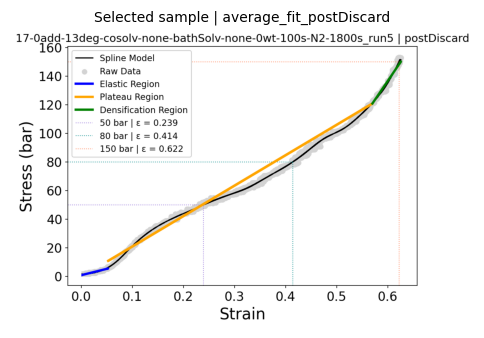

#### New fabrication 1

,unit,sample mean,sample SD,rep 1,rep 2
Thickness,um,132.6451,0.0260,132.6711,132.6190
Elastic Modulus,bar,230.9484,3.8703,227.0781,234.8187
Yield Strength,bar,33.3629,0.8108,32.5521,34.1737
Pore Fraction,fraction,0.4955,0.0260,0.5214,0.4695
Pore Fraction Unsubtracted,fraction,0.5509,0.0295,0.5214,0.5804
Slope Plateau,bar,83.8333,4.2662,88.0995,79.5671
Slope Densification,bar,599.7254,68.1279,531.5976,667.8533
Creep Strain,strain,0.0728,0.0069,0.0797,0.0659
Strain at 50 bar,strain,0.3852,0.0506,0.3346,0.4357
Strain at 80 bar,strain,0.5655,0.0340,0.5316,0.5995


,name,Trial,Good Fit,Good Fit Score,Good Fit Breakdown
0,psf-reproducibility-2026-11-16_psf-water_V1_re...,sample 5,True,89,"{""elastic_r2"": {""pts"": 28, ""max"": 30, ""note"": ..."
1,psf-reproducibility-2026-11-16_psf-water_V1_re...,sample 6,True,88,"{""elastic_r2"": {""pts"": 28, ""max"": 30, ""note"": ..."


Discard reasons: none recorded


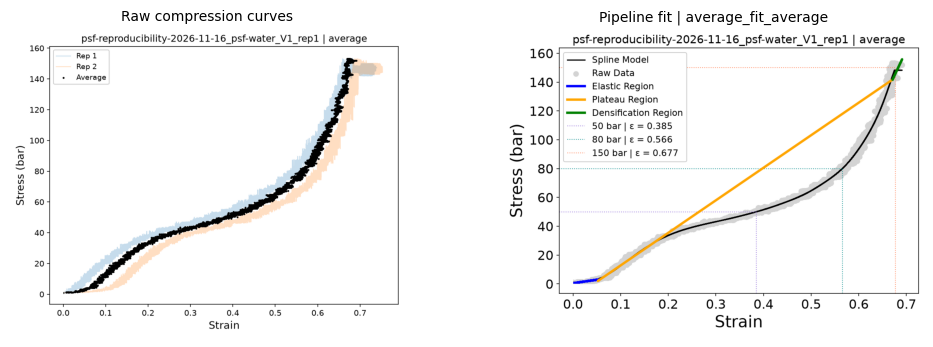

Plot folder: data/plots/run-psf-reproducibility-2026-11-16-psf-water/psf-reproducibility-2026-11-16_psf-water_V1_rep1
Plot files: averageFits/average_fit_average.png, averageFits/Derivatives_average_fit_average.png, averageFits/raw_average_curves.png, averageFits/Unsubtracted_average_fit_average.png, averageFits/Unsubtracted_Derivatives_average_fit_average.png, Comparison_CV.png, rep-1/Derivatives_rep-1.png, rep-1/Pre-Processing_rep-1.png, rep-1/Segmentation_rep-1.png, rep-1/Unsubtracted_Derivatives_rep-1.png, rep-1/Unsubtracted_Segmentation_rep-1.png, rep-2/Derivatives_rep-2.png, rep-2/Pre-Processing_rep-2.png, rep-2/Segmentation_rep-2.png, rep-2/Unsubtracted_Derivatives_rep-2.png, rep-2/Unsubtracted_Segmentation_rep-2.png


#### New fabrication 2

,unit,sample mean,sample SD,rep 1,rep 2
Thickness,um,142.5790,2.0576,144.6366,140.5215
Elastic Modulus,bar,203.0954,0.0000,203.0954,26.8209
Yield Strength,bar,40.3954,0.0000,40.3954,4.6018
Pore Fraction,fraction,0.4878,0.0000,0.4878,0.6247
Pore Fraction Unsubtracted,fraction,0.4878,0.0000,0.4878,0.6282
Slope Plateau,bar,121.9937,0.0000,121.9937,241.9796
Slope Densification,bar,429.7669,0.0000,429.7669,611.1264
Creep Strain,strain,0.1673,0.0000,0.1673,0.0917
Strain at 50 bar,strain,0.3368,0.0480,0.2888,0.3848
Strain at 80 bar,strain,0.4693,0.0000,0.4693,0.5422


,name,Trial,Good Fit,Good Fit Score,Good Fit Breakdown
2,psf-reproducibility-2026-11-16_psf-water_V1_re...,sample 9,True,86,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."
3,psf-reproducibility-2026-11-16_psf-water_V1_re...,sample 10,False,31,"{""elastic_r2"": {""pts"": 28, ""max"": 30, ""note"": ..."


Discard reasons: 1 failed due to plateau slope >= elastic modulus, no real transition


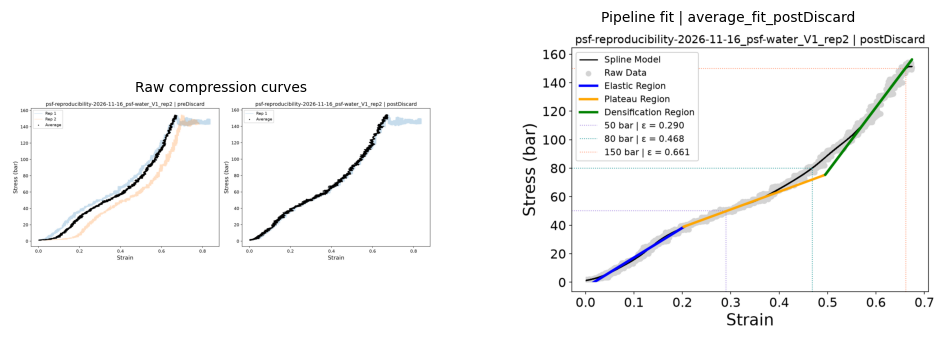

Plot folder: data/plots/run-psf-reproducibility-2026-11-16-psf-water/psf-reproducibility-2026-11-16_psf-water_V1_rep2
Plot files: averageFits/average_fit_postDiscard.png, averageFits/average_fit_preDiscard.png, averageFits/Derivatives_average_fit_postDiscard.png, averageFits/Derivatives_average_fit_preDiscard.png, averageFits/raw_average_curves.png, averageFits/Unsubtracted_average_fit_postDiscard.png, averageFits/Unsubtracted_average_fit_preDiscard.png, averageFits/Unsubtracted_Derivatives_average_fit_postDiscard.png, averageFits/Unsubtracted_Derivatives_average_fit_preDiscard.png, Comparison_CV_postDiscard.png, Comparison_CV_preDiscard.png, rep-1/Derivatives_rep-1.png, rep-1/Pre-Processing_rep-1.png, rep-1/Segmentation_rep-1.png, rep-1/Unsubtracted_Derivatives_rep-1.png, rep-1/Unsubtracted_Segmentation_rep-1.png, rep-2/Derivatives_rep-2.png, rep-2/Pre-Processing_rep-2.png, rep-2/Segmentation_rep-2.png, rep-2/Unsubtracted_Derivatives_rep-2.png, rep-2/Unsubtracted_Segmentation_rep-2.pn

#### New fabrication 3

,unit,sample mean,sample SD,rep 1,rep 2
Thickness,um,134.9724,0.3933,134.5791,135.3657
Elastic Modulus,bar,221.1530,0.0000,221.1530,106.5432
Yield Strength,bar,31.2108,0.0000,31.2108,8.7501
Pore Fraction,fraction,0.5987,0.0000,0.5987,0.5300
Pore Fraction Unsubtracted,fraction,0.5987,0.0000,0.5987,0.6573
Slope Plateau,bar,85.0733,0.0000,85.0733,200.7131
Slope Densification,bar,480.5198,0.0000,480.5198,601.5339
Creep Strain,strain,0.0572,0.0000,0.0572,0.0549
Strain at 50 bar,strain,0.3912,0.0322,0.3591,0.4234
Strain at 80 bar,strain,0.5880,0.0000,0.5880,0.5915


,name,Trial,Good Fit,Good Fit Score,Good Fit Breakdown
4,psf-reproducibility-2026-11-16_psf-water_V1_re...,sample 13,True,90,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."
5,psf-reproducibility-2026-11-16_psf-water_V1_re...,sample 14,False,32,"{""elastic_r2"": {""pts"": 26, ""max"": 30, ""note"": ..."


Discard reasons: 1 failed due to plateau slope >= elastic modulus, no real transition


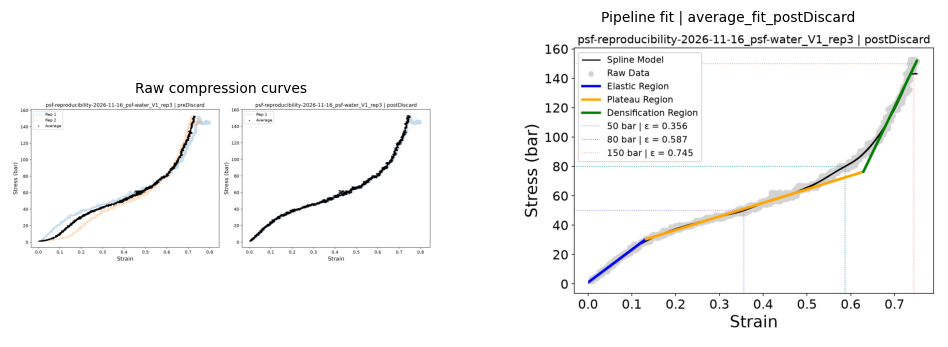

Plot folder: data/plots/run-psf-reproducibility-2026-11-16-psf-water/psf-reproducibility-2026-11-16_psf-water_V1_rep3
Plot files: averageFits/average_fit_postDiscard.png, averageFits/average_fit_preDiscard.png, averageFits/Derivatives_average_fit_postDiscard.png, averageFits/Derivatives_average_fit_preDiscard.png, averageFits/raw_average_curves.png, averageFits/Unsubtracted_average_fit_postDiscard.png, averageFits/Unsubtracted_average_fit_preDiscard.png, averageFits/Unsubtracted_Derivatives_average_fit_postDiscard.png, averageFits/Unsubtracted_Derivatives_average_fit_preDiscard.png, Comparison_CV_postDiscard.png, Comparison_CV_preDiscard.png, rep-1/Derivatives_rep-1.png, rep-1/Pre-Processing_rep-1.png, rep-1/Segmentation_rep-1.png, rep-1/Unsubtracted_Derivatives_rep-1.png, rep-1/Unsubtracted_Segmentation_rep-1.png, rep-2/Derivatives_rep-2.png, rep-2/Pre-Processing_rep-2.png, rep-2/Segmentation_rep-2.png, rep-2/Unsubtracted_Derivatives_rep-2.png, rep-2/Unsubtracted_Segmentation_rep-2.pn

### PSf / PolarClean V2

,unit,selected mean,selected SD
Thickness,um,148.4449,4.0717
Elastic Modulus,bar,273.4708,14.3032
Yield Strength,bar,30.0178,1.5532
Pore Fraction,fraction,0.5186,0.0652
Pore Fraction Unsubtracted,fraction,0.5186,0.0652
Slope Plateau,bar,101.0316,23.8978
Slope Densification,bar,571.3819,174.1075
Creep Strain,strain,0.0637,0.0106
Strain at 50 bar,strain,0.3294,0.0677
Strain at 80 bar,strain,0.5128,0.0761


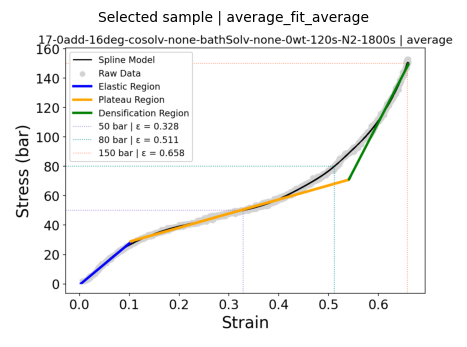

#### New fabrication 1

,unit,sample mean,sample SD,rep 1,rep 2
Thickness,um,137.1676,0.1233,137.2909,137.0442
Elastic Modulus,bar,256.0428,46.9601,303.0030,209.0827
Yield Strength,bar,30.3438,2.9410,33.2848,27.4028
Pore Fraction,fraction,0.5060,0.0276,0.5336,0.4784
Pore Fraction Unsubtracted,fraction,0.5699,0.0363,0.5336,0.6063
Slope Plateau,bar,61.7164,2.5570,59.1594,64.2734
Slope Densification,bar,673.2992,28.5297,644.7695,701.8289
Creep Strain,strain,0.0529,0.0026,0.0555,0.0503
Strain at 50 bar,strain,0.4465,0.0779,0.3686,0.5244
Strain at 80 bar,strain,0.5891,0.0496,0.5395,0.6387


,name,Trial,Good Fit,Good Fit Score,Good Fit Breakdown
6,psf-reproducibility-2026-11-16_psf-water_V2_re...,sample 17,True,87,"{""elastic_r2"": {""pts"": 27, ""max"": 30, ""note"": ..."
7,psf-reproducibility-2026-11-16_psf-water_V2_re...,sample 18,True,91,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."


Discard reasons: none recorded


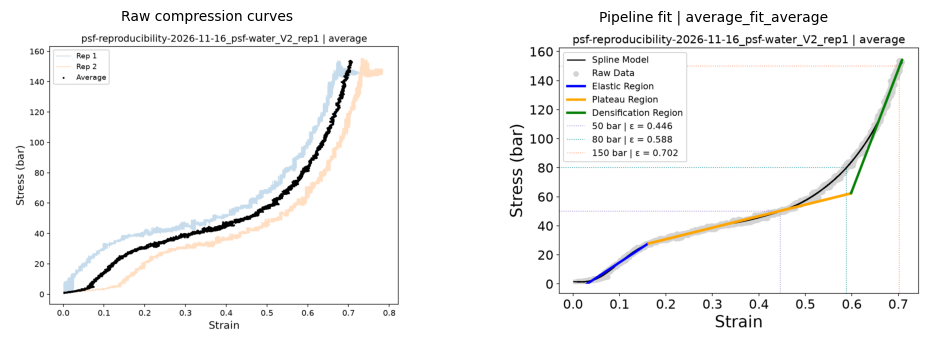

Plot folder: data/plots/run-psf-reproducibility-2026-11-16-psf-water/psf-reproducibility-2026-11-16_psf-water_V2_rep1
Plot files: averageFits/average_fit_average.png, averageFits/Derivatives_average_fit_average.png, averageFits/raw_average_curves.png, averageFits/Unsubtracted_average_fit_average.png, averageFits/Unsubtracted_Derivatives_average_fit_average.png, Comparison_CV.png, rep-1/Derivatives_rep-1.png, rep-1/Pre-Processing_rep-1.png, rep-1/Segmentation_rep-1.png, rep-1/Unsubtracted_Derivatives_rep-1.png, rep-1/Unsubtracted_Segmentation_rep-1.png, rep-2/Derivatives_rep-2.png, rep-2/Pre-Processing_rep-2.png, rep-2/Segmentation_rep-2.png, rep-2/Unsubtracted_Derivatives_rep-2.png, rep-2/Unsubtracted_Segmentation_rep-2.png


#### New fabrication 2

,unit,sample mean,sample SD,rep 1,rep 2
Thickness,um,146.1973,0.1975,145.9998,146.3948
Elastic Modulus,bar,206.0751,1.5686,204.5065,207.6436
Yield Strength,bar,37.8745,4.4831,42.3576,33.3913
Pore Fraction,fraction,0.4431,0.0032,0.4399,0.4463
Pore Fraction Unsubtracted,fraction,0.4766,0.0368,0.4399,0.5134
Slope Plateau,bar,98.2240,1.5223,99.7463,96.7017
Slope Densification,bar,554.0202,164.1488,389.8715,718.1690
Creep Strain,strain,0.0720,0.0212,0.0932,0.0508
Strain at 50 bar,strain,0.3441,0.0350,0.3091,0.3790
Strain at 80 bar,strain,0.5038,0.0180,0.4858,0.5218


,name,Trial,Good Fit,Good Fit Score,Good Fit Breakdown
9,psf-reproducibility-2026-11-16_psf-water_V2_re...,sample 21,True,88,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."
8,psf-reproducibility-2026-11-16_psf-water_V2_re...,sample 22,True,96,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."


Discard reasons: none recorded


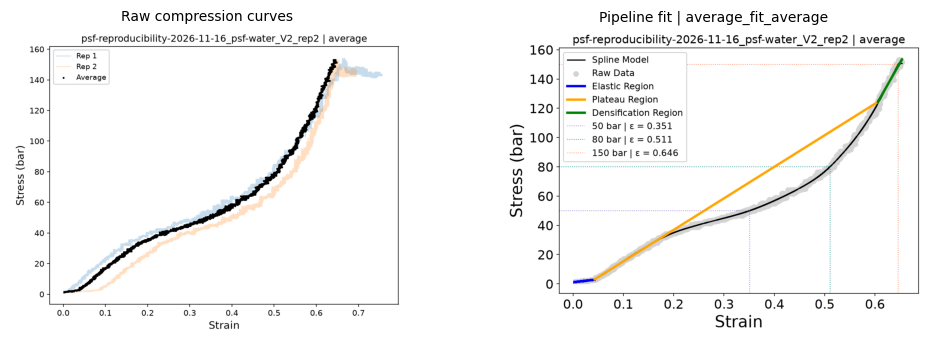

Plot folder: data/plots/run-psf-reproducibility-2026-11-16-psf-water/psf-reproducibility-2026-11-16_psf-water_V2_rep2
Plot files: averageFits/average_fit_average.png, averageFits/Derivatives_average_fit_average.png, averageFits/raw_average_curves.png, averageFits/Unsubtracted_average_fit_average.png, averageFits/Unsubtracted_Derivatives_average_fit_average.png, Comparison_CV.png, rep-1/Derivatives_rep-1.png, rep-1/Pre-Processing_rep-1.png, rep-1/Segmentation_rep-1.png, rep-1/Unsubtracted_Derivatives_rep-1.png, rep-1/Unsubtracted_Segmentation_rep-1.png, rep-2/Derivatives_rep-2.png, rep-2/Pre-Processing_rep-2.png, rep-2/Segmentation_rep-2.png, rep-2/Unsubtracted_Derivatives_rep-2.png, rep-2/Unsubtracted_Segmentation_rep-2.png


#### New fabrication 3

,unit,sample mean,sample SD,rep 1,rep 2
Thickness,um,137.4534,2.8235,134.6299,140.2768
Elastic Modulus,bar,158.4442,39.0470,197.4912,119.3972
Yield Strength,bar,14.9987,0.7352,15.7339,14.2634
Pore Fraction,fraction,0.5257,0.0163,0.5421,0.5094
Pore Fraction Unsubtracted,fraction,0.5624,0.0203,0.5421,0.5828
Slope Plateau,bar,66.6486,5.9936,60.6550,72.6423
Slope Densification,bar,740.0037,10.2497,729.7540,750.2534
Creep Strain,strain,0.0429,0.0017,0.0412,0.0446
Strain at 50 bar,strain,0.5212,0.0238,0.4974,0.5451
Strain at 80 bar,strain,0.6088,0.0186,0.5903,0.6274


,name,Trial,Good Fit,Good Fit Score,Good Fit Breakdown
10,psf-reproducibility-2026-11-16_psf-water_V2_re...,sample 25,True,92,"{""elastic_r2"": {""pts"": 28, ""max"": 30, ""note"": ..."
11,psf-reproducibility-2026-11-16_psf-water_V2_re...,sample 26,True,83,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."


Discard reasons: none recorded


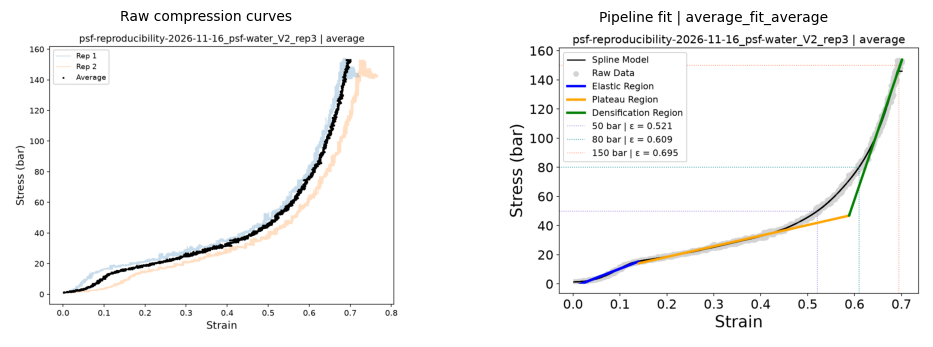

Plot folder: data/plots/run-psf-reproducibility-2026-11-16-psf-water/psf-reproducibility-2026-11-16_psf-water_V2_rep3
Plot files: averageFits/average_fit_average.png, averageFits/Derivatives_average_fit_average.png, averageFits/raw_average_curves.png, averageFits/Unsubtracted_average_fit_average.png, averageFits/Unsubtracted_Derivatives_average_fit_average.png, Comparison_CV.png, rep-1/Derivatives_rep-1.png, rep-1/Pre-Processing_rep-1.png, rep-1/Segmentation_rep-1.png, rep-1/Unsubtracted_Derivatives_rep-1.png, rep-1/Unsubtracted_Segmentation_rep-1.png, rep-2/Derivatives_rep-2.png, rep-2/Pre-Processing_rep-2.png, rep-2/Segmentation_rep-2.png, rep-2/Unsubtracted_Derivatives_rep-2.png, rep-2/Unsubtracted_Segmentation_rep-2.png


### PSf / PolarClean V3

,unit,selected mean,selected SD
Thickness,um,134.2710,2.2272
Elastic Modulus,bar,132.7290,16.2452
Yield Strength,bar,20.5817,1.6974
Pore Fraction,fraction,0.6203,0.0536
Pore Fraction Unsubtracted,fraction,0.6203,0.0536
Slope Plateau,bar,73.9771,13.0891
Slope Densification,bar,937.8037,126.5517
Creep Strain,strain,0.0415,0.0027
Strain at 50 bar,strain,0.5372,0.0630
Strain at 80 bar,strain,0.6400,0.0428


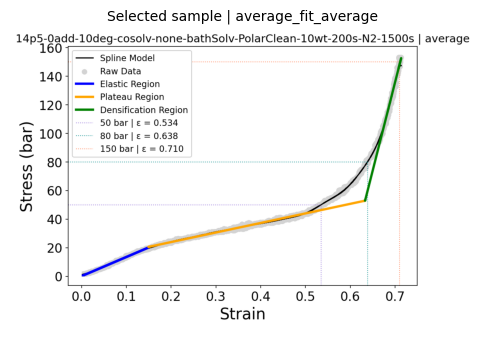

### PSf / PolarClean V4

,unit,selected mean,selected SD
Thickness,um,136.6265,6.7330
Elastic Modulus,bar,240.2241,60.4907
Yield Strength,bar,29.9378,2.6908
Pore Fraction,fraction,0.6394,0.0296
Pore Fraction Unsubtracted,fraction,0.6577,0.0106
Slope Plateau,bar,73.5494,5.6716
Slope Densification,bar,813.7520,26.5789
Creep Strain,strain,0.0391,0.0012
Strain at 50 bar,strain,0.4778,0.0678
Strain at 80 bar,strain,0.6664,0.0122


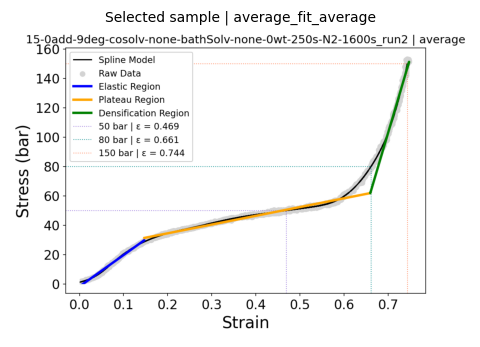

#### New fabrication 1

,unit,sample mean,sample SD,rep 1,rep 2
Thickness,um,134.9390,0.1779,135.1169,134.7611
Elastic Modulus,bar,152.9151,8.1014,161.0165,144.8138
Yield Strength,bar,24.1755,1.9585,26.1340,22.2171
Pore Fraction,fraction,0.5420,0.0338,0.5758,0.5083
Pore Fraction Unsubtracted,fraction,0.5420,0.0338,0.5758,0.5083
Slope Plateau,bar,96.5220,2.6287,93.8933,99.1507
Slope Densification,bar,656.8244,227.1213,429.7031,883.9458
Creep Strain,strain,0.0581,0.0161,0.0742,0.0420
Strain at 50 bar,strain,0.4016,0.0081,0.3936,0.4097
Strain at 80 bar,strain,0.5425,0.0152,0.5577,0.5273


,name,Trial,Good Fit,Good Fit Score,Good Fit Breakdown
12,psf-reproducibility-2026-11-16_psf-water_V4_re...,sample 29,True,85,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."
13,psf-reproducibility-2026-11-16_psf-water_V4_re...,sample 30,True,85,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."


Discard reasons: none recorded


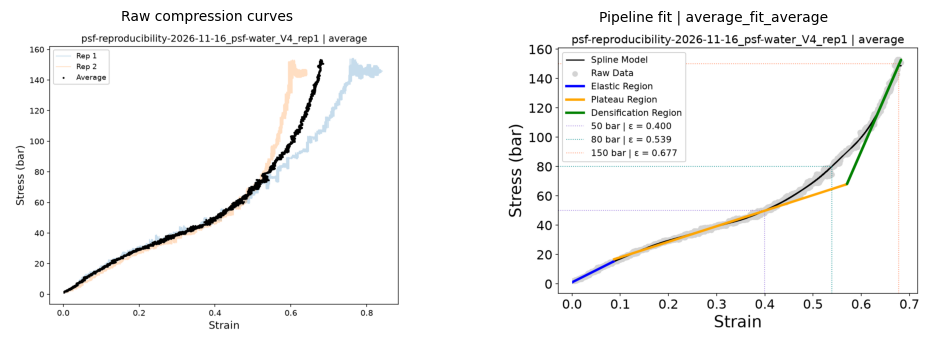

Plot folder: data/plots/run-psf-reproducibility-2026-11-16-psf-water/psf-reproducibility-2026-11-16_psf-water_V4_rep1
Plot files: averageFits/average_fit_average.png, averageFits/Derivatives_average_fit_average.png, averageFits/raw_average_curves.png, averageFits/Unsubtracted_average_fit_average.png, averageFits/Unsubtracted_Derivatives_average_fit_average.png, Comparison_CV.png, rep-1/Derivatives_rep-1.png, rep-1/Pre-Processing_rep-1.png, rep-1/Segmentation_rep-1.png, rep-1/Unsubtracted_Derivatives_rep-1.png, rep-1/Unsubtracted_Segmentation_rep-1.png, rep-2/Derivatives_rep-2.png, rep-2/Pre-Processing_rep-2.png, rep-2/Segmentation_rep-2.png, rep-2/Unsubtracted_Derivatives_rep-2.png, rep-2/Unsubtracted_Segmentation_rep-2.png


#### New fabrication 2

,unit,sample mean,sample SD,rep 1,rep 2
Thickness,um,131.8077,4.6328,136.4405,127.1748
Elastic Modulus,bar,131.4403,1.6491,133.0894,129.7912
Yield Strength,bar,17.4112,2.1669,15.2443,19.5780
Pore Fraction,fraction,0.6155,0.0300,0.6455,0.5854
Pore Fraction Unsubtracted,fraction,0.6155,0.0300,0.6455,0.5854
Slope Plateau,bar,51.2735,3.8878,47.3858,55.1613
Slope Densification,bar,868.8153,26.6022,842.2131,895.4175
Creep Strain,strain,0.0364,0.0021,0.0343,0.0384
Strain at 50 bar,strain,0.5698,0.0332,0.6030,0.5367
Strain at 80 bar,strain,0.6527,0.0335,0.6862,0.6192


,name,Trial,Good Fit,Good Fit Score,Good Fit Breakdown
14,psf-reproducibility-2026-11-16_psf-water_V4_re...,sample 33,True,94,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."
15,psf-reproducibility-2026-11-16_psf-water_V4_re...,sample 34,True,94,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."


Discard reasons: none recorded


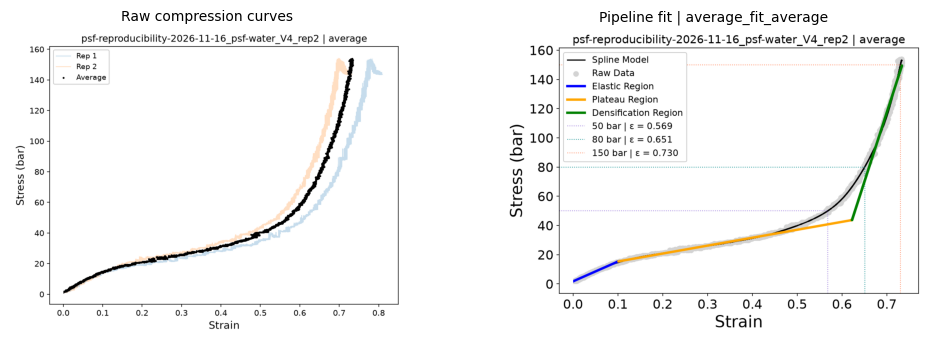

Plot folder: data/plots/run-psf-reproducibility-2026-11-16-psf-water/psf-reproducibility-2026-11-16_psf-water_V4_rep2
Plot files: averageFits/average_fit_average.png, averageFits/Derivatives_average_fit_average.png, averageFits/raw_average_curves.png, averageFits/Unsubtracted_average_fit_average.png, averageFits/Unsubtracted_Derivatives_average_fit_average.png, Comparison_CV.png, rep-1/Derivatives_rep-1.png, rep-1/Pre-Processing_rep-1.png, rep-1/Segmentation_rep-1.png, rep-1/Unsubtracted_Derivatives_rep-1.png, rep-1/Unsubtracted_Segmentation_rep-1.png, rep-2/Derivatives_rep-2.png, rep-2/Pre-Processing_rep-2.png, rep-2/Segmentation_rep-2.png, rep-2/Unsubtracted_Derivatives_rep-2.png, rep-2/Unsubtracted_Segmentation_rep-2.png


#### New fabrication 3

,unit,sample mean,sample SD,rep 1,rep 2
Thickness,um,132.9183,2.6064,130.3118,135.5247
Elastic Modulus,bar,166.7402,2.3635,164.3767,169.1037
Yield Strength,bar,28.4871,0.3079,28.1792,28.7950
Pore Fraction,fraction,0.5945,0.1403,0.7348,0.4541
Pore Fraction Unsubtracted,fraction,0.6961,0.0387,0.7348,0.6575
Slope Plateau,bar,100.6438,12.2722,88.3716,112.9161
Slope Densification,bar,659.9593,53.1573,606.8020,713.1166
Creep Strain,strain,0.0421,0.0037,0.0458,0.0384
Strain at 50 bar,strain,0.4788,0.0521,0.4267,0.5309
Strain at 80 bar,strain,0.6861,0.0064,0.6925,0.6797


,name,Trial,Good Fit,Good Fit Score,Good Fit Breakdown
16,psf-reproducibility-2026-11-16_psf-water_V4_re...,sample 37,True,96,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."
17,psf-reproducibility-2026-11-16_psf-water_V4_re...,sample 38,True,89,"{""elastic_r2"": {""pts"": 29, ""max"": 30, ""note"": ..."


Discard reasons: none recorded


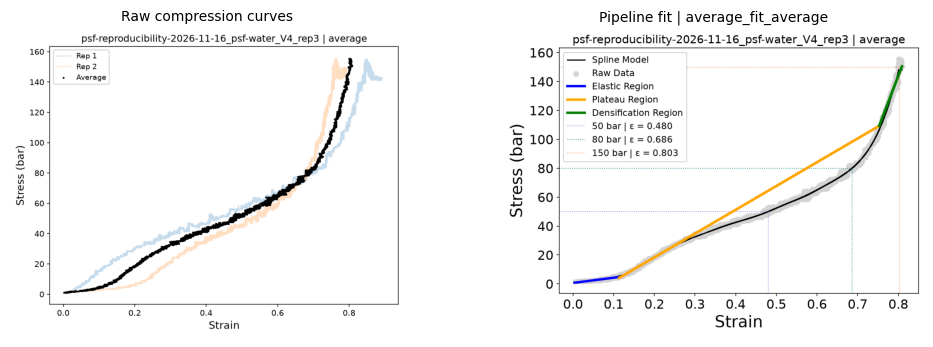

Plot folder: data/plots/run-psf-reproducibility-2026-11-16-psf-water/psf-reproducibility-2026-11-16_psf-water_V4_rep3
Plot files: averageFits/average_fit_average.png, averageFits/Derivatives_average_fit_average.png, averageFits/raw_average_curves.png, averageFits/Unsubtracted_average_fit_average.png, averageFits/Unsubtracted_Derivatives_average_fit_average.png, Comparison_CV.png, rep-1/Derivatives_rep-1.png, rep-1/Pre-Processing_rep-1.png, rep-1/Segmentation_rep-1.png, rep-1/Unsubtracted_Derivatives_rep-1.png, rep-1/Unsubtracted_Segmentation_rep-1.png, rep-2/Derivatives_rep-2.png, rep-2/Pre-Processing_rep-2.png, rep-2/Segmentation_rep-2.png, rep-2/Unsubtracted_Derivatives_rep-2.png, rep-2/Unsubtracted_Segmentation_rep-2.png


### PSf / PolarClean V5

,unit,selected mean,selected SD
Thickness,um,157.1229,2.3045
Elastic Modulus,bar,255.5237,19.0745
Yield Strength,bar,25.0148,0.9582
Pore Fraction,fraction,0.6619,0.0340
Pore Fraction Unsubtracted,fraction,0.6619,0.0340
Slope Plateau,bar,108.7970,11.3802
Slope Densification,bar,918.7358,29.2812
Creep Strain,strain,0.0386,0.0030
Strain at 50 bar,strain,0.3879,0.0775
Strain at 80 bar,strain,0.6487,0.0319


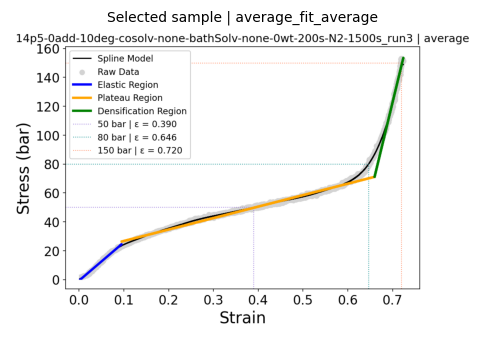

### Primospire / NMP V1

,unit,selected mean,selected SD
Thickness,um,134.5390,1.1346
Elastic Modulus,bar,580.7147,34.4944
Yield Strength,bar,57.9027,7.5652
Pore Fraction,fraction,0.2763,0.0215
Pore Fraction Unsubtracted,fraction,0.3120,0.0242
Slope Plateau,bar,299.6816,17.0544
Slope Densification,bar,423.7085,15.3180
Creep Strain,strain,0.1130,0.0044
Strain at 50 bar,strain,0.1367,0.0282
Strain at 80 bar,strain,0.2146,0.0265


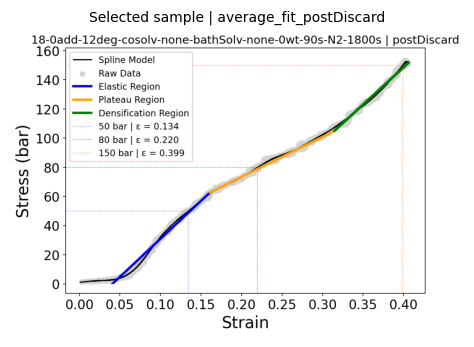

### Primospire / NMP V2

,unit,selected mean,selected SD
Thickness,um,144.9473,3.4316
Elastic Modulus,bar,708.9732,216.2625
Yield Strength,bar,39.0607,3.9546
Pore Fraction,fraction,0.2787,0.0201
Pore Fraction Unsubtracted,fraction,0.2787,0.0201
Slope Plateau,bar,210.9946,18.2996
Slope Densification,bar,618.0875,11.0848
Creep Strain,strain,0.1044,0.0047
Strain at 50 bar,strain,0.1055,0.0274
Strain at 80 bar,strain,0.2411,0.0255


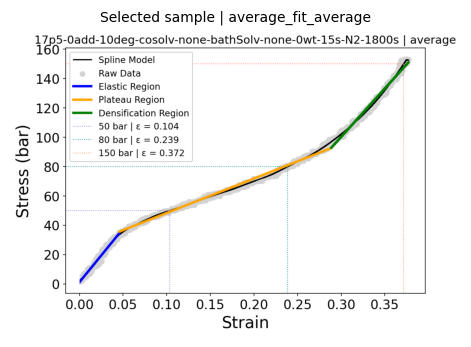

### Primospire / NMP V3

,unit,selected mean,selected SD
Thickness,um,130.3804,1.2421
Elastic Modulus,bar,767.8349,181.2366
Yield Strength,bar,47.7862,8.6560
Pore Fraction,fraction,0.3355,0.0143
Pore Fraction Unsubtracted,fraction,0.3389,0.0199
Slope Plateau,bar,206.0915,23.0516
Slope Densification,bar,421.8029,34.4230
Creep Strain,strain,0.1348,0.0055
Strain at 50 bar,strain,0.0913,0.0083
Strain at 80 bar,strain,0.2319,0.0356


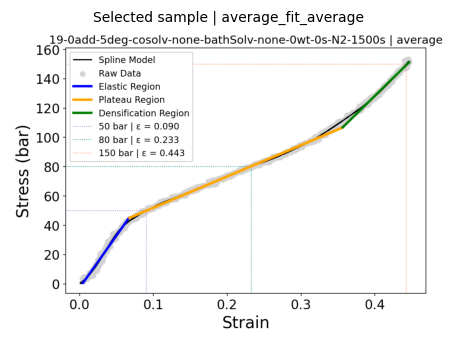

### Primospire / NMP V4

,unit,selected mean,selected SD
Thickness,um,126.2474,4.2140
Elastic Modulus,bar,579.6934,50.8095
Yield Strength,bar,48.3157,2.1958
Pore Fraction,fraction,0.3344,0.0381
Pore Fraction Unsubtracted,fraction,0.3344,0.0381
Slope Plateau,bar,193.0208,33.5025
Slope Densification,bar,455.2767,34.4224
Creep Strain,strain,0.1302,0.0007
Strain at 50 bar,strain,0.1066,0.0183
Strain at 80 bar,strain,0.2588,0.0451


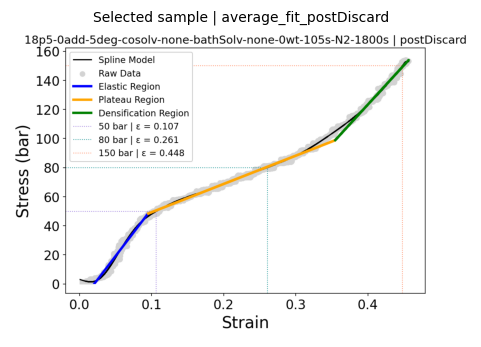

### Primospire / NMP V5

,unit,selected mean,selected SD
Thickness,um,143.9466,2.8900
Elastic Modulus,bar,429.9737,112.2383
Yield Strength,bar,47.7743,2.5334
Pore Fraction,fraction,0.3658,0.0245
Pore Fraction Unsubtracted,fraction,0.3658,0.0245
Slope Plateau,bar,178.9769,3.7955
Slope Densification,bar,476.8184,6.5918
Creep Strain,strain,0.1072,0.0016
Strain at 50 bar,strain,0.1421,0.0300
Strain at 80 bar,strain,0.3047,0.0265


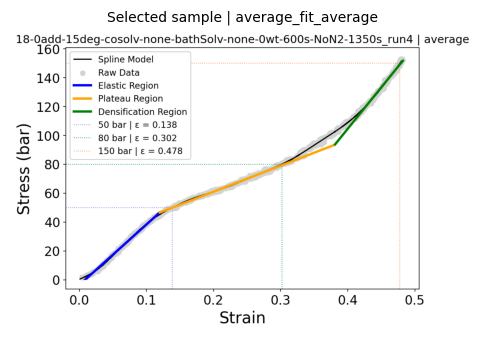

In [8]:
coupon_frames = []
for path in sorted(results.glob('*/reps.csv')):
    coupon_frames.append(pd.read_csv(path))
coupons = pd.concat(coupon_frames, ignore_index=True)
coupons['sample'] = coupons['name'].str.split(' | rep ', regex=False).str[0]
assert set(coupons['sample']).issubset(new['name'])
print(f"{len(new)} fabrication rows and {len(coupons)} coupon fit rows.")
display(new[keys + ['repeat', 'fabricated', 'bottle age (days)', 'Toe Subtracted',
                    'Toe Fit Mode', 'Toe Shift Policy', 'Discarded Fit Reasons']])

def curve_panel(paths):
    available = [(label, path) for label, path in paths if path.is_file()]
    if not available:
        print('No matching curve images found.')
        return
    fig, axes = plt.subplots(1, len(available), figsize=(6 * len(available), 4), squeeze=False)
    for ax, (label, path) in zip(axes.flat, available):
        ax.imshow(plt.imread(path))
        ax.set_title(label, fontsize=10)
        ax.axis('off')
    plt.show()

def fit_image(directory):
    candidates = ['average_fit_postDiscard.png', 'average_fit_average.png', 'average_fit_preDiscard.png']
    return next((directory / file for file in candidates if (directory / file).exists()),
                directory / candidates[0])

for _, row in selected.iterrows():
    display(Markdown(f"### {row['chemistry']} {row['validation_id']}"))
    history_dir = report / 'assets/fit' / row['condition'].replace('-', '_')
    history_props = pd.DataFrame({
        'unit': units,
        'selected mean': {prop: row[f'{prop} Mean'] for prop in units},
        'selected SD': {prop: row.get(f'{prop} SD') for prop in units},
    }).dropna(subset=['selected mean'])
    display(history_props.round(4))
    historical_fit = fit_image(history_dir)
    curve_panel([(f'Selected sample | {historical_fit.stem}', historical_fit)])
    samples = new.loc[new['chemistry'].eq(row['chemistry'])
                      & new['validation_id'].eq(row['validation_id'])].sort_values('repeat')
    for _, sample in samples.iterrows():
        display(Markdown(f"#### New fabrication {sample['repeat']}"))
        trials = coupons.loc[coupons['sample'].eq(sample['name'])].sort_values('name')
        measurements = pd.DataFrame({
            'unit': units,
            'sample mean': {prop: sample[f'{prop} Mean'] for prop in units},
            'sample SD': {prop: sample.get(f'{prop} SD') for prop in units},
        })
        for _, trial in trials.iterrows():
            measurements[trial['name'].rsplit(' | ', 1)[-1]] = {
                prop: trial.get(prop) for prop in units}
        display(measurements.round(4))
        display(trials[['name', 'Trial', 'Good Fit', 'Good Fit Score', 'Good Fit Breakdown']])
        print('Discard reasons:', sample['Discarded Fit Reasons'] if
              pd.notna(sample['Discarded Fit Reasons']) else 'none recorded')
        directory = root / 'data/plots' / f"run-{campaign}-{sample['batch']}" / sample['name']
        avg = directory / 'averageFits'
        fitted = fit_image(avg)
        curve_panel([('Raw compression curves', avg / 'raw_average_curves.png'),
                     (f'Pipeline fit | {fitted.stem}', fitted)])
        diagnostics = sorted(directory.rglob('*.png'))
        print('Plot folder:', directory.relative_to(root).as_posix())
        print('Plot files:', ', '.join(path.relative_to(directory).as_posix() for path in diagnostics))